<a href="https://colab.research.google.com/github/alokchoudharyguliya/ML/blob/main/Titanic/%5BProject%5DTitanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Local->Titanic

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pylab import rcParams
rcParams['figure.figsize']=8,6
import warnings
warnings.filterwarnings('ignore')

In [ ]:
datas=pd.read_csv('/content/Titanic.csv')

In [ ]:
datas

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [ ]:
datas.shape

(891, 12)

In [ ]:
datas.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
datas.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
datas.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [ ]:
datas.isnull().sum().sort_values(ascending=True)

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
Age            177
Cabin          687
dtype: int64

In [ ]:
datas.isna().sum().sort_values(ascending=True)/len(datas)*100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Embarked        0.224467
Age            19.865320
Cabin          77.104377
dtype: float64

In [ ]:
datas['Cabin'].value_counts()

B96 B98        4
G6             4
C23 C25 C27    4
C22 C26        3
F33            3
              ..
E34            1
C7             1
C54            1
E36            1
C148           1
Name: Cabin, Length: 147, dtype: int64

In [ ]:
datas.drop('Cabin',axis=1,inplace=True)

In [ ]:
datas.shape

(891, 11)

In [ ]:
# here cabin feature has more than 50 % empty values therefore we drop it
datas.isna().sum().sort_values(ascending=False)/len(datas)*100

Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
dtype: float64

In [ ]:
# sns.distplot(x=datas['Age'],data=datas)

In [ ]:
datas['Age'].mean()

29.69911764705882

In [ ]:
datas['Age'].median()

28.0

In [ ]:
datas['Age'].mode()

0    24.0
Name: Age, dtype: float64

In [ ]:
datas['Age']=datas['Age'].fillna(datas['Age'].mean())

In [ ]:
datas['Age'].isnull().sum()

0

In [ ]:
datas.Embarked.unique()

array(['S', 'C', 'Q', nan], dtype=object)

In [ ]:
datas.Pclass.unique()

array([3, 1, 2])

In [ ]:
datas['Parch'].value_counts()

0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: Parch, dtype: int64

In [ ]:
numerical_cols=datas.select_dtypes(include=np.number).columns
for i in numerical_cols:
  print(datas[i].value_counts)

<bound method IndexOpsMixin.value_counts of 0        1
1        2
2        3
3        4
4        5
      ... 
886    887
887    888
888    889
889    890
890    891
Name: PassengerId, Length: 891, dtype: int64>
<bound method IndexOpsMixin.value_counts of 0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64>
<bound method IndexOpsMixin.value_counts of 0      3
1      1
2      3
3      1
4      3
      ..
886    2
887    1
888    3
889    1
890    3
Name: Pclass, Length: 891, dtype: int64>
<bound method IndexOpsMixin.value_counts of 0      22.000000
1      38.000000
2      26.000000
3      35.000000
4      35.000000
         ...    
886    27.000000
887    19.000000
888    29.699118
889    26.000000
890    32.000000
Name: Age, Length: 891, dtype: float64>
<bound method IndexOpsMixin.value_counts of 0      1
1      1
2      0
3      1
4      0
      ..
886    0
887    0
888    1
889    0
890    0
Name:

In [ ]:
categorical_cols=datas.select_dtypes(include='object').columns
for i in categorical_cols:
  print(datas[i].value_counts)

<bound method IndexOpsMixin.value_counts of 0                                Braund, Mr. Owen Harris
1      Cumings, Mrs. John Bradley (Florence Briggs Th...
2                                 Heikkinen, Miss. Laina
3           Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                               Allen, Mr. William Henry
                             ...                        
886                                Montvila, Rev. Juozas
887                         Graham, Miss. Margaret Edith
888             Johnston, Miss. Catherine Helen "Carrie"
889                                Behr, Mr. Karl Howell
890                                  Dooley, Mr. Patrick
Name: Name, Length: 891, dtype: object>
<bound method IndexOpsMixin.value_counts of 0        male
1      female
2      female
3      female
4        male
        ...  
886      male
887    female
888    female
889      male
890      male
Name: Sex, Length: 891, dtype: object>
<bound method IndexOpsMixin.value_counts of 0       

In [ ]:
# y=data['Survived']

In [ ]:
# data.

**Data Visualization**

<Axes: >

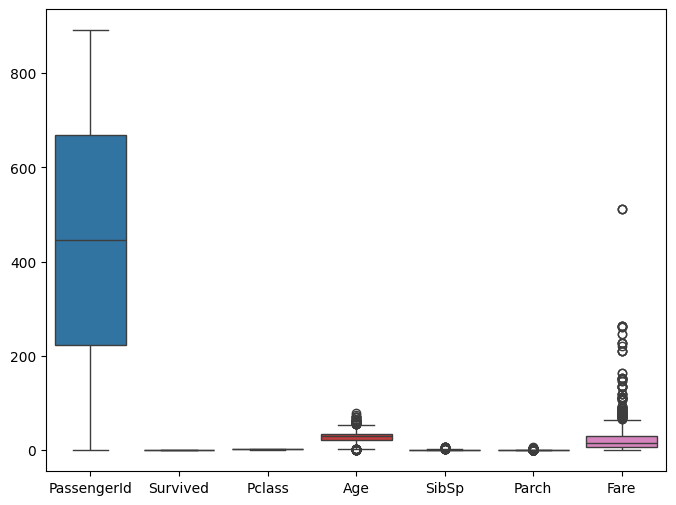

In [ ]:
sns.boxplot(data=datas)

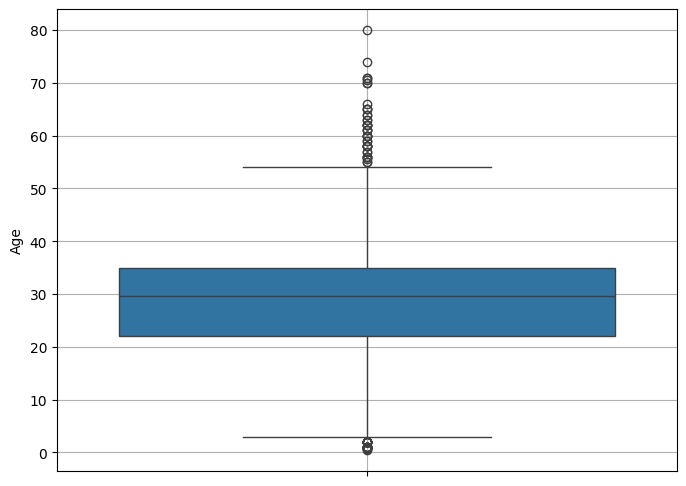

In [ ]:
sns.boxplot(data=datas['Age'])
plt.grid()
# here we should delete the outliers i.e. handle them

In [ ]:
datas[datas['Age']>55]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,S
33,34,0,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,S
54,55,0,1,"Ostby, Mr. Engelhart Cornelius",male,65.0,0,1,113509,61.9792,C
94,95,0,3,"Coxon, Mr. Daniel",male,59.0,0,0,364500,7.2500,S
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,C
116,117,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,Q
152,153,0,3,"Meo, Mr. Alfonzo",male,55.5,0,0,A.5. 11206,8.0500,S
170,171,0,1,"Van der hoef, Mr. Wyckoff",male,61.0,0,0,111240,33.5000,S
174,175,0,1,"Smith, Mr. James Clinch",male,56.0,0,0,17764,30.6958,C
195,196,1,1,"Lurette, Miss. Elise",female,58.0,0,0,PC 17569,146.5208,C


In [ ]:
len(datas[datas['Age']>55])

40

In [ ]:
datas[datas['Age']>55][['Name','Age','Survived']]


,Name,Age,Survived
11,"Bonnell, Miss. Elizabeth",58.0,1
33,"Wheadon, Mr. Edward H",66.0,0
54,"Ostby, Mr. Engelhart Cornelius",65.0,0
94,"Coxon, Mr. Daniel",59.0,0
96,"Goldschmidt, Mr. George B",71.0,0
116,"Connors, Mr. Patrick",70.5,0
152,"Meo, Mr. Alfonzo",55.5,0
170,"Van der hoef, Mr. Wyckoff",61.0,0
174,"Smith, Mr. James Clinch",56.0,0
195,"Lurette, Miss. Elise",58.0,1


In [ ]:
datas[datas['Age']>55][['Name','Age','Survived']].index


Int64Index([ 11,  33,  54,  94,  96, 116, 152, 170, 174, 195, 232, 252, 268,
            275, 280, 326, 366, 438, 456, 467, 483, 487, 493, 545, 555, 570,
            587, 625, 626, 630, 647, 659, 672, 684, 694, 745, 772, 829, 851,
            879],
           dtype='int64')

In [ ]:
# X=data.drop('Survived',axis=1)

In [ ]:
df=datas.drop(axis=0,'Age')

In [ ]:
sns.boxplot(df['Age'])

NameError: name 'df' is not defined

In [ ]:
datas.shape

(891, 11)

In [ ]:
# X.columns

In [ ]:
# categorical_data
# data.describe(include='object')